---
## 1. **Business Problem**

### **Business objective**

The agricultural business wants to understand which environmental and farm-management factors are most important for predicting **crop yield**.

A reliable yield prediction model could help farmers and agricultural managers:

* estimate expected crop production;
* optimise fertilizer and pesticide usage;
* make better irrigation decisions;
* identify high-performing crop varieties;
* improve resource allocation;
* support agricultural planning.

Our machine-learning objective is therefore:

> **Build a Random Forest regression model that predicts crop yield and identify the features that contribute most strongly to those predictions.**

### **Import dataset**

In [1]:
import pandas as pd

In [2]:
# Load dataset
file_path = "../data/Crop_yield.csv"
df = pd.read_csv(file_path)

* **Target:** `Yield`
* **Numerical features:** `Temperature`, `Rainfall`, `Fertilizer_Usage`, `Pesticide_Usage`
* **Categorical features:** `Region`, `Soil_Type`, `Crop_Variety`
* **Binary feature:** `Irrigation`

## 2. **Import Libraries**

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

---

## 3. **Plotting Function**


In [4]:
from plot import style_plot

---

## 4. **Load and Inspect the Dataset**

In [5]:
display(df.head())

,Region,Temperature,Rainfall,Soil_Type,Fertilizer_Usage,Pesticide_Usage,Irrigation,Crop_Variety,Yield
0,East,23.152156,803.362573,Clayey,204.792011,20.767590,1,Variety B,40.316318
1,West,19.382419,571.567670,Sandy,256.201737,49.290242,0,Variety A,26.846639
2,North,27.895890,-8.699637,Loamy,222.202626,25.316121,0,Variety C,-0.323558
3,East,26.741361,897.426194,Loamy,187.984090,17.115362,0,Variety C,45.440871
4,East,19.090286,649.384694,Loamy,110.459549,24.068804,1,Variety B,35.478118


In [6]:
# Check the dimensions:
display(df.shape)

(1000, 9)

In [7]:
# Check the columns:
display(df.columns)


Index(['Region', 'Temperature', 'Rainfall', 'Soil_Type', 'Fertilizer_Usage',
       'Pesticide_Usage', 'Irrigation', 'Crop_Variety', 'Yield'],
      dtype='str')

In [8]:
# Check data types:
display(df.dtypes)

Region                  str
Temperature         float64
Rainfall            float64
Soil_Type               str
Fertilizer_Usage    float64
Pesticide_Usage     float64
Irrigation            int64
Crop_Variety            str
Yield               float64
dtype: object

In [9]:
# Check info:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Region            1000 non-null   str    
 1   Temperature       1000 non-null   float64
 2   Rainfall          1000 non-null   float64
 3   Soil_Type         1000 non-null   str    
 4   Fertilizer_Usage  1000 non-null   float64
 5   Pesticide_Usage   1000 non-null   float64
 6   Irrigation        1000 non-null   int64  
 7   Crop_Variety      1000 non-null   str    
 8   Yield             1000 non-null   float64
dtypes: float64(5), int64(1), str(3)
memory usage: 70.4 KB


None

In [10]:
# Describe the dataset:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Temperature,1000.0,25.250082,4.979438,8.065931,21.823442,25.429272,28.687443,42.479389
Rainfall,1000.0,498.018579,199.537595,-167.900036,353.178888,494.189894,644.162691,1084.150513
Fertilizer_Usage,1000.0,171.253446,71.697830,50.519129,109.618317,170.676081,232.056661,299.762375
Pesticide_Usage,1000.0,30.014739,11.478614,10.025101,20.345079,30.340789,39.393116,49.993970
Irrigation,1000.0,0.513000,0.500081,0.000000,0.000000,1.000000,1.000000,1.000000
Yield,1000.0,26.263842,10.181351,-8.426900,18.873992,26.324512,33.537327,54.415047


In [11]:
# Check for missing values:
display(df.isnull().sum())

Region              0
Temperature         0
Rainfall            0
Soil_Type           0
Fertilizer_Usage    0
Pesticide_Usage     0
Irrigation          0
Crop_Variety        0
Yield               0
dtype: int64

In [12]:
# Check for duplicate rows:
display(df.duplicated().sum())

np.int64(0)

---

## 5. **Understand the Target Variable**

Our target is `Yield`.

In [13]:
# Describe the 'Yield' column:

display(df["Yield"].describe())

count    1000.000000
mean       26.263842
std        10.181351
min        -8.426900
25%        18.873992
50%        26.324512
75%        33.537327
max        54.415047
Name: Yield, dtype: float64

---
### **Distribution of yield**

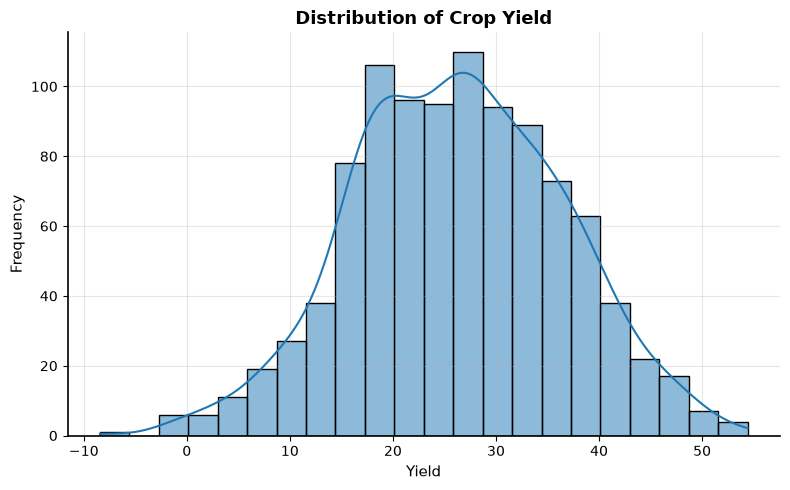

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Yield",
    kde=True,
    ax=ax
)

style_plot(
    ax,
    title="Distribution of Crop Yield",
    xlabel="Yield",
    ylabel="Frequency",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

## 6. **Explore Numerical Features**

In [15]:
numeric_features = [
    "Temperature",
    "Rainfall",
    "Fertilizer_Usage",
    "Pesticide_Usage",
    "Irrigation"
]

df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Temperature,1000.0,25.250082,4.979438,8.065931,21.823442,25.429272,28.687443,42.479389
Rainfall,1000.0,498.018579,199.537595,-167.900036,353.178888,494.189894,644.162691,1084.150513
Fertilizer_Usage,1000.0,171.253446,71.697830,50.519129,109.618317,170.676081,232.056661,299.762375
Pesticide_Usage,1000.0,30.014739,11.478614,10.025101,20.345079,30.340789,39.393116,49.993970
Irrigation,1000.0,0.513000,0.500081,0.000000,0.000000,1.000000,1.000000,1.000000


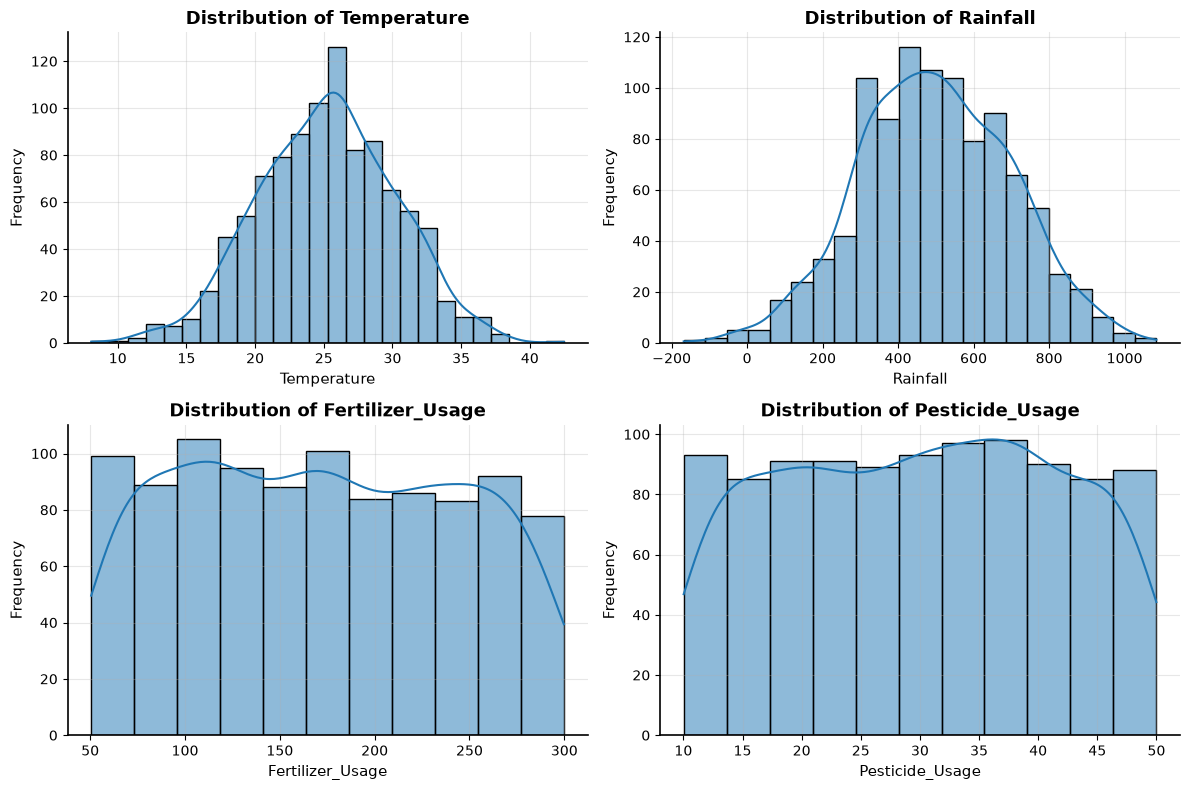

In [16]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)
for ax, feature in zip(axes.flat, numeric_features):

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax
    )

    style_plot(
        ax,
        title=f"Distribution of {feature}",
        xlabel=feature,
        ylabel="Frequency",
        spine_width=1.2
    )

plt.tight_layout()
plt.show()

---

## 7. **Explore Categorical Features**

In [17]:
categorical_features = [
    "Region",
    "Soil_Type",
    "Crop_Variety"
]

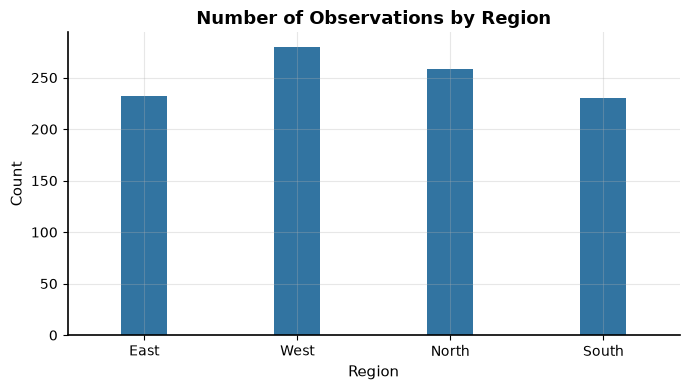

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Region",
    ax=ax,
    width = .3
)

style_plot(
    ax,
    title="Number of Observations by Region",
    xlabel="Region",
    ylabel="Count",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

---

## 8. **Explore Relationships with Yield**

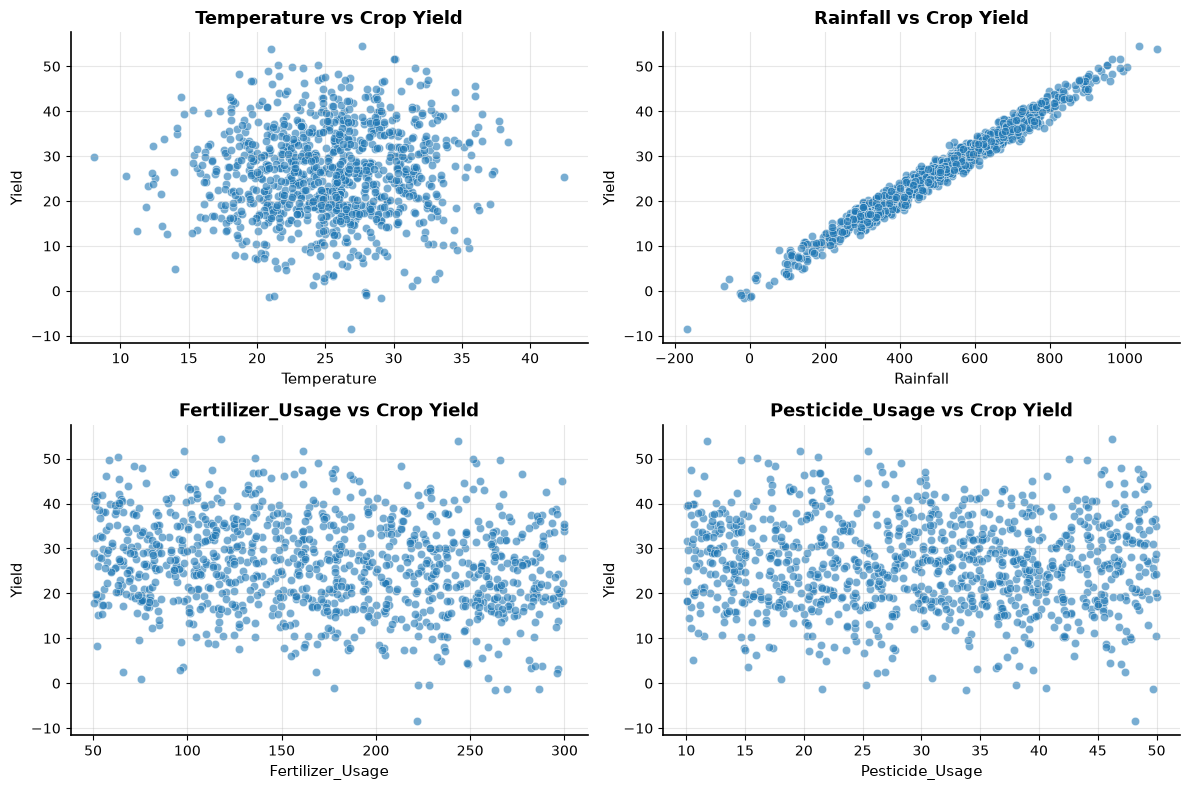

In [19]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

for ax, feature in zip(axes.flat, numeric_features):

    sns.scatterplot(
        data=df,
        x=feature,
        y="Yield",
        alpha=0.6,
        ax=ax
    )

    style_plot(
        ax,
        title=f"{feature} vs Crop Yield",
        xlabel=feature,
        ylabel="Yield",
        spine_width=1.2
    )

plt.tight_layout()
plt.show()

This gives us an initial understanding of whether there are visible relationships between the numerical predictors and crop yield.

---

## 9. **Correlation Analysis**

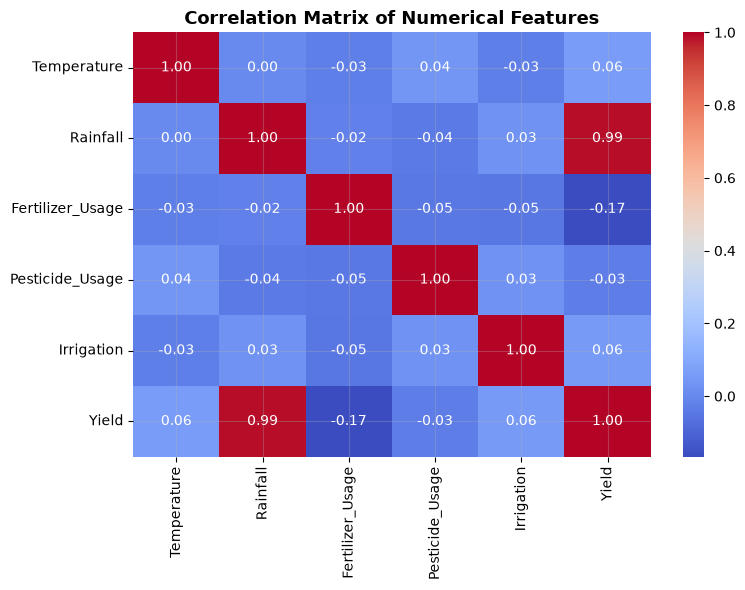

In [20]:
correlation = df[
    numeric_features + ["Yield"]
].corr()

correlation

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=ax
)

style_plot(
    ax,
    title="Correlation Matrix of Numerical Features",
    remove_spine = False
)

plt.tight_layout()
plt.show()

---

## 10. __Prepare the Data__


In [21]:
X = df.drop(columns="Yield")
y = df["Yield"]


---

## 11. **Encode Categorical Variables**

Random Forest in scikit-learn requires numerical input, so we need to encode:

* `Region`
* `Soil_Type`
* `Crop_Variety`

A straightforward approach for this exercise is one-hot encoding:

In [22]:
X_encoded = pd.get_dummies(
    X,
    drop_first=True
)

In [23]:
X_encoded.shape

(1000, 12)

---

## 12. __Task 1 — Create `train_rf_model`__

Now we implement your exercise exactly.

The function must:

1. receive an encoded DataFrame;
2. receive the target column name;
3. receive the number of estimators;
4. split the data;
5. train a Random Forest;
6. predict on the test set;
7. calculate RMSE and R²;
8. return the model, RMSE and R².

In [24]:
def train_rf_model(data, target, n_estimators):
    
    # Separate features and target
    X = data.drop(columns=target)
    y = data[target]
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=23
    )
    
    # Create Random Forest model
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=23
    )
    
    # Train model
    model.fit(X_train, y_train)
    
    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )
    
    r2 = r2_score(
        y_test,
        y_pred
    )
    
    return model, rmse, r2

---

## 13. __Prepare the Encoded Dataset for the Function__

The function expects the **target to be inside the DataFrame**, so combine the encoded predictors and target:

In [25]:
encoded_df = X_encoded.copy()

encoded_df["Yield"] = y

In [26]:
encoded_df.head()

,Temperature,Rainfall,Fertilizer_Usage,Pesticide_Usage,Irrigation,Region_North,Region_South,Region_West,Soil_Type_Loamy,Soil_Type_Sandy,Crop_Variety_Variety B,Crop_Variety_Variety C,Yield
0,23.152156,803.362573,204.792011,20.767590,1,False,False,False,False,False,True,False,40.316318
1,19.382419,571.567670,256.201737,49.290242,0,False,False,True,False,True,False,False,26.846639
2,27.895890,-8.699637,222.202626,25.316121,0,True,False,False,True,False,False,True,-0.323558
3,26.741361,897.426194,187.984090,17.115362,0,False,False,False,True,False,False,True,45.440871
4,19.090286,649.384694,110.459549,24.068804,1,False,False,False,True,False,True,False,35.478118


---

## 14. __Test Task 1__

Let's make sure the function works:

In [27]:
model_50, rmse_50, r2_50 = train_rf_model(
    encoded_df,
    "Yield",
    50
)

print(f"RMSE: {rmse_50:.4f}")
print(f"R²: {r2_50:.4f}")

RMSE: 0.8828
R²: 0.9924


---

## 15. **Exercise 2 — Train 50, 100 and 200 Trees**

Now use the function three times.

In [29]:
results = {}

for n_estimators in [50, 100, 200]:
    
    model, rmse, r2 = train_rf_model(
        encoded_df,
        "Yield",
        n_estimators
    )
    
    results[n_estimators] = {
        "model": model,
        "RMSE": rmse,
        "R²": r2
    }

    # Inspect the result
    display(results)

{50: {'model': RandomForestRegressor(n_estimators=50, random_state=23),
  'RMSE': np.float64(0.882787801497763),
  'R²': 0.9923507399810414}}

{50: {'model': RandomForestRegressor(n_estimators=50, random_state=23),
  'RMSE': np.float64(0.882787801497763),
  'R²': 0.9923507399810414},
 100: {'model': RandomForestRegressor(random_state=23),
  'RMSE': np.float64(0.8654915335962515),
  'R²': 0.9926475441555008}}

{50: {'model': RandomForestRegressor(n_estimators=50, random_state=23),
  'RMSE': np.float64(0.882787801497763),
  'R²': 0.9923507399810414},
 100: {'model': RandomForestRegressor(random_state=23),
  'RMSE': np.float64(0.8654915335962515),
  'R²': 0.9926475441555008},
 200: {'model': RandomForestRegressor(n_estimators=200, random_state=23),
  'RMSE': np.float64(0.8620623003155069),
  'R²': 0.9927056922378575}}

In [30]:
# A cleaner performance table:
results_df = pd.DataFrame({
    n: {
        "RMSE": values["RMSE"],
        "R²": values["R²"]
    }
    for n, values in results.items()
}).T

results_df.index.name = "Number of Trees"

results_df

,RMSE,R²
Number of Trees,,
50,0.882788,0.992351
100,0.865492,0.992648
200,0.862062,0.992706


---

## 16. **Visualise Model Performance**

### **R² comparison**

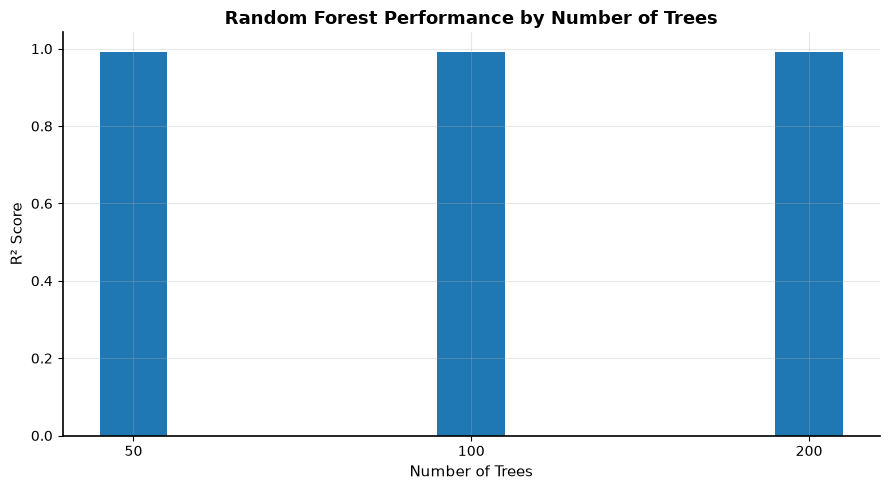

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    results_df.index.astype(str),
    results_df["R²"], width = 0.2
)

style_plot(
    ax,
    title="Random Forest Performance by Number of Trees",
    xlabel="Number of Trees",
    ylabel="R² Score",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

### **RMSE comparison**

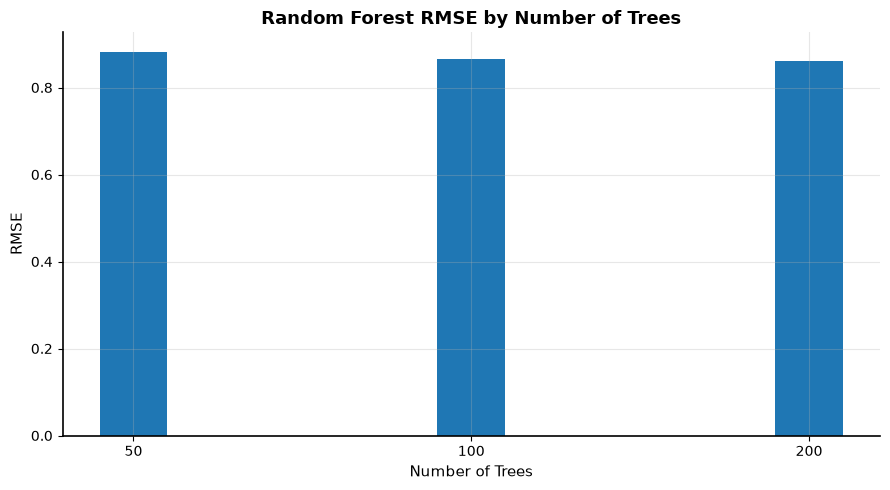

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
   results_df.index.astype(str),
    results_df["RMSE"], width=0.2
)

style_plot(
    ax,
    title="Random Forest RMSE by Number of Trees",
    xlabel="Number of Trees",
    ylabel="RMSE",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

### __How to choose the best model__

For RMSE:

> **Lower is better.**

For R²:

> **Higher is better.**

You can identify the best model programmatically:


In [41]:
best_n_estimators = results_df["R²"].idxmax()

best_model = results[best_n_estimators]["model"]

print(f"Best number of trees: {best_n_estimators}")
print(f"RMSE: {results_df.loc[best_n_estimators, 'RMSE']:.4f}")
print(f"R²: {results_df.loc[best_n_estimators, 'R²']:.4f}")


Best number of trees: 200
RMSE: 0.8621
R²: 0.9927


--- 

## 17. __Exercise 3 — Feature Importance__

The exercise specifically asks us to use the **last trained Random Forest model**.

We therefore retrieve the feature importance from the model trained with **200 trees**.

In [42]:
last_model = results[200]["model"]

feature_importance = pd.Series(
    last_model.feature_importances_,
    index=X_encoded.columns
).sort_values(
    ascending=False
)

feature_importance

Rainfall                  0.978673
Fertilizer_Usage          0.016680
Temperature               0.002135
Pesticide_Usage           0.001177
Irrigation                0.000290
Crop_Variety_Variety C    0.000203
Soil_Type_Loamy           0.000155
Region_West               0.000146
Region_North              0.000145
Soil_Type_Sandy           0.000139
Crop_Variety_Variety B    0.000133
Region_South              0.000124
dtype: float64

--- 

## 18. __Plot Feature Importance__

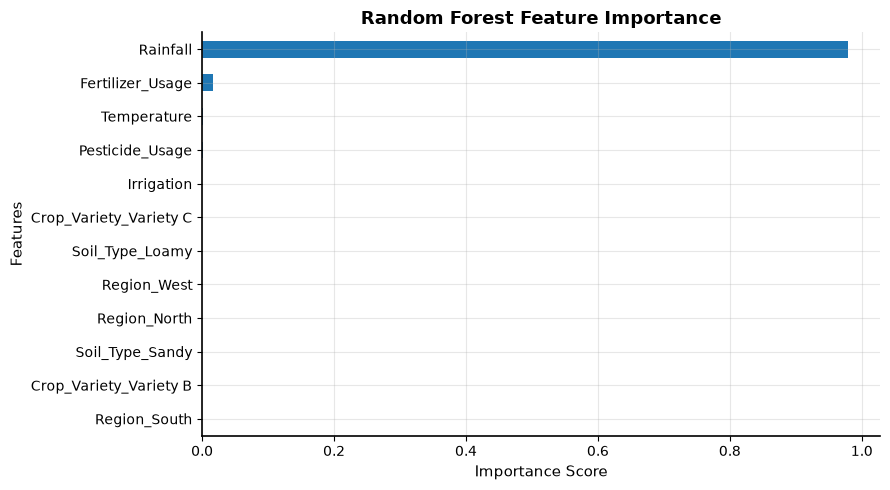

In [44]:
fig, ax = plt.subplots(figsize=(9, 5))

feature_importance.sort_values().plot(
    kind="barh",
    ax=ax
)

style_plot(
    ax,
    title="Random Forest Feature Importance",
    xlabel="Importance Score",
    ylabel="Features",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

---

## 19. **Identify the Top Features**

In [45]:
top_features = feature_importance.head(10)

top_features

Rainfall                  0.978673
Fertilizer_Usage          0.016680
Temperature               0.002135
Pesticide_Usage           0.001177
Irrigation                0.000290
Crop_Variety_Variety C    0.000203
Soil_Type_Loamy           0.000155
Region_West               0.000146
Region_North              0.000145
Soil_Type_Sandy           0.000139
dtype: float64

In [46]:
top_features_percentage = (
    top_features * 100
).round(2)

top_features_percentage

Rainfall                  97.87
Fertilizer_Usage           1.67
Temperature                0.21
Pesticide_Usage            0.12
Irrigation                 0.03
Crop_Variety_Variety C     0.02
Soil_Type_Loamy            0.02
Region_West                0.01
Region_North               0.01
Soil_Type_Sandy            0.01
dtype: float64

---

## 20. __Actual vs Predicted Plot__


In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=23
)

y_pred = best_model.predict(X_test)


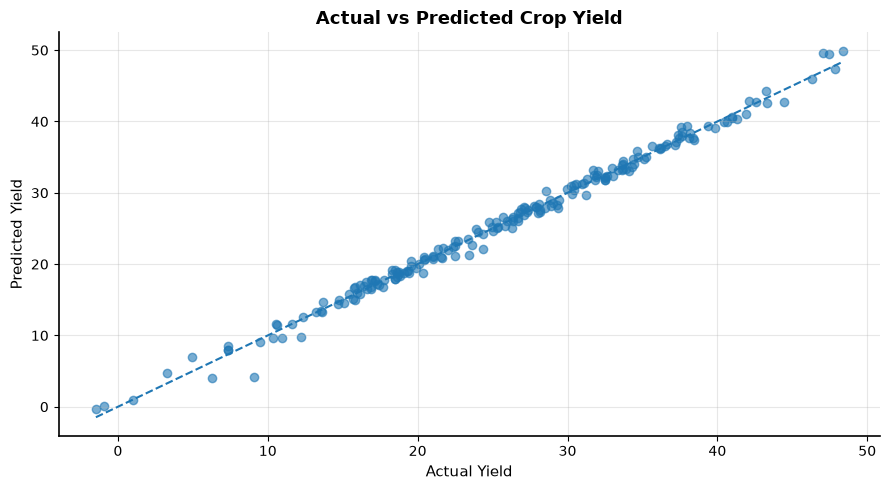

In [48]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

ax.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

style_plot(
    ax,
    title="Actual vs Predicted Crop Yield",
    xlabel="Actual Yield",
    ylabel="Predicted Yield",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

## 21. __Residual Analysis__

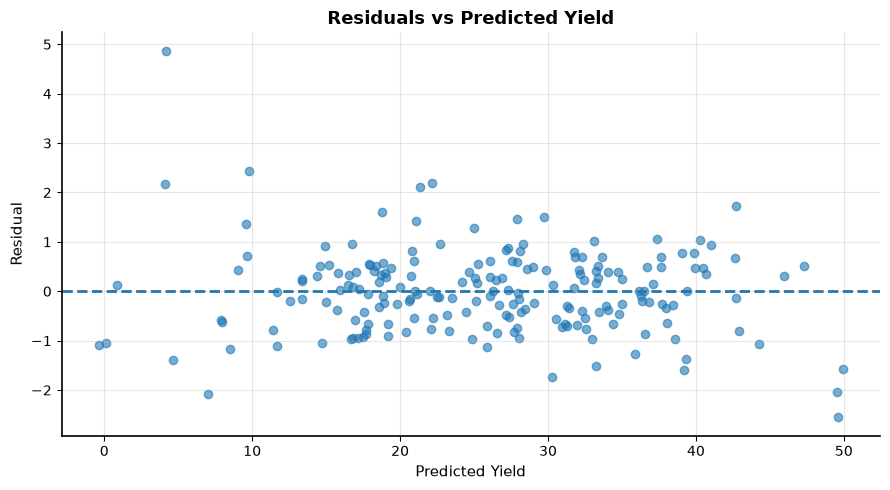

In [50]:
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

ax.axhline(
    0,
    linestyle="--",
    linewidth = 2
)

style_plot(
    ax,
    title="Residuals vs Predicted Yield",
    xlabel="Predicted Yield",
    ylabel="Residual",
    spine_width=1.2
)

plt.tight_layout()
plt.show()

---

## 22. __Final Model Evaluation__

In [51]:
# Create a concise model summary:

final_metrics = pd.DataFrame({
    "Metric": ["RMSE", "R²"],
    "Value": [
        results[best_n_estimators]["RMSE"],
        results[best_n_estimators]["R²"]
    ]
})

final_metrics

,Metric,Value
0,RMSE,0.862062
1,R²,0.992706


---

## 23. __Business Interpretation__

> Rainfall was the most influential predictor of crop yield in the Random Forest model. This suggests that variations in rainfall contain substantial information for estimating expected agricultural output. Agricultural planning could therefore benefit from incorporating rainfall forecasts into yield estimation and resource allocation.